In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

conn = sqlite3.connect('perpustakaan.db')
cursor = conn.cursor()

cursor.execute("PRAGMA foreign_keys = ON;")

cursor.executescript("""
DROP TABLE IF EXISTS peminjaman;
DROP TABLE IF EXISTS buku;
DROP TABLE IF EXISTS anggota;
""")

cursor.execute("""
CREATE TABLE buku (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    judul TEXT NOT NULL,
    penulis TEXT NOT NULL,
    tahun INTEGER NOT NULL
);
""")

cursor.execute("""
CREATE TABLE anggota (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    nama TEXT NOT NULL,
    email TEXT UNIQUE NOT NULL
);
""")

cursor.execute("""
CREATE TABLE peminjaman (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    id_anggota INTEGER NOT NULL,
    id_buku INTEGER NOT NULL,
    tgl_pinjam DATE NOT NULL,
    tgl_kembali DATE,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku) REFERENCES buku(id)
);
""")

conn.commit()
print("Tabel buku, anggota, dan peminjaman berhasil dibuat!")

Tabel buku, anggota, dan peminjaman berhasil dibuat!


In [2]:
# 1a. Menambahkan 5 data buku dan 3 data anggota
data_buku = [
    ('Laskar Pelangi', 'Andrea Hirata', 2005),
    ('Bumi Manusia', 'Pramoedya Ananta Toer', 1980),
    ('Filosofi Teras', 'Henry Manampiring', 2018),
    ('Atomic Habits', 'James Clear', 2018),
    ('Clean Code', 'Robert C. Martin', 2008)
]

data_anggota = [
    ('Budi Santoso', 'budi.santoso@email.com'),
    ('Siti Aminah', 'siti.aminah@email.com'),
    ('Andi Wijaya', 'andi.wijaya@email.com')
]

cursor.executemany("INSERT INTO buku (judul, penulis, tahun) VALUES (?, ?, ?);", data_buku)
cursor.executemany("INSERT INTO anggota (nama, email) VALUES (?, ?);", data_anggota)

# 1b. Menambahkan 4 transaksi peminjaman (minimal 1 tgl_kembali bernilai NULL/None)
data_peminjaman = [
    (1, 1, '2026-10-01', '2026-10-06'),  # Budi pinjam Laskar Pelangi (5 hari)
    (1, 3, '2026-10-10', '2026-10-18'),  # Budi pinjam Filosofi Teras (8 hari)
    (2, 4, '2026-10-12', '2026-10-15'),  # Siti pinjam Atomic Habits (3 hari)
    (3, 5, '2026-10-20', None)           # Andi pinjam Clean Code (Belum dikembalikan / NULL)
]

cursor.executemany("""
INSERT INTO peminjaman (id_anggota, id_buku, tgl_pinjam, tgl_kembali)
VALUES (?, ?, ?, ?);
""", data_peminjaman)

conn.commit()
print("Data buku, anggota, dan transaksi peminjaman berhasil dimasukkan!")

Data buku, anggota, dan transaksi peminjaman berhasil dimasukkan!


In [3]:
# 1c. Menampilkan daftar peminjaman lengkap menggunakan JOIN
query_1c = """
SELECT
    p.id AS id_peminjaman,
    a.nama AS nama_anggota,
    b.judul AS judul_buku,
    p.tgl_pinjam,
    p.tgl_kembali
FROM peminjaman p
JOIN anggota a ON p.id_anggota = a.id
JOIN buku b ON p.id_buku = b.id;
"""

print("=== 1c. Daftar Peminjaman Lengkap ===")
cursor.execute(query_1c)
for row in cursor.fetchall():
    print(row)

# 1d. Menghitung jumlah total buku yang dipinjam oleh masing-masing anggota
query_1d = """
SELECT
    a.nama AS nama_anggota,
    COUNT(p.id) AS total_buku_dipinjam
FROM anggota a
LEFT JOIN peminjaman p ON a.id = p.id_anggota
GROUP BY a.id, a.nama
ORDER BY total_buku_dipinjam DESC;
"""

print("\n=== 1d. Total Buku Dipinjam per Anggota ===")
cursor.execute(query_1d)
for row in cursor.fetchall():
    print(row)

=== 1c. Daftar Peminjaman Lengkap ===
(1, 'Budi Santoso', 'Laskar Pelangi', '2026-10-01', '2026-10-06')
(2, 'Budi Santoso', 'Filosofi Teras', '2026-10-10', '2026-10-18')
(3, 'Siti Aminah', 'Atomic Habits', '2026-10-12', '2026-10-15')
(4, 'Andi Wijaya', 'Clean Code', '2026-10-20', None)

=== 1d. Total Buku Dipinjam per Anggota ===
('Budi Santoso', 2)
('Siti Aminah', 1)
('Andi Wijaya', 1)


In [4]:
# 2a. Membuat DataFrame pandas dari hasil query 1c dan 1d
df_peminjaman = pd.read_sql_query(query_1c, conn)
df_agregasi = pd.read_sql_query(query_1d, conn)

print("--- DataFrame Peminjaman (1c) ---")
display(df_peminjaman)

print("\n--- DataFrame Agregasi Anggota (1d) ---")
display(df_agregasi)

# 2b. Eksplorasi Data Sederhana: Menghitung durasi peminjaman & identifikasi pola
df_peminjaman['tgl_pinjam'] = pd.to_datetime(df_peminjaman['tgl_pinjam'])
df_peminjaman['tgl_kembali'] = pd.to_datetime(df_peminjaman['tgl_kembali'])

# Hitung selisih hari (hasilnya akan NaN jika tgl_kembali masih NULL)
df_peminjaman['durasi_hari'] = (df_peminjaman['tgl_kembali'] - df_peminjaman['tgl_pinjam']).dt.days
df_peminjaman['status'] = df_peminjaman['tgl_kembali'].apply(
    lambda x: 'Sudah Kembali' if pd.notnull(x) else 'Masih Dipinjam'
)

print("\n--- Hasil Eksplorasi Durasi & Status Peminjaman ---")
display(df_peminjaman[['id_peminjaman', 'nama_anggota', 'judul_buku', 'durasi_hari', 'status']])

# Ringkasan statistik pola peminjaman
rata_durasi = df_peminjaman['durasi_hari'].mean()
belum_kembali = df_peminjaman['tgl_kembali'].isna().sum()
peminjam_teraktif = df_agregasi.iloc[0]['nama_anggota']

print(f"\nRingkasan Pola Peminjaman:")
print(f"- Rata-rata durasi peminjaman (buku yang sudah kembali): {rata_durasi:.2f} hari")
print(f"- Jumlah transaksi aktif (belum dikembalikan): {belum_kembali} buku")
print(f"- Anggota paling aktif meminjam: {peminjam_teraktif} ({df_agregasi.iloc[0]['total_buku_dipinjam']} buku)")

--- DataFrame Peminjaman (1c) ---


,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Budi Santoso,Laskar Pelangi,2026-10-01,2026-10-06
1,2,Budi Santoso,Filosofi Teras,2026-10-10,2026-10-18
2,3,Siti Aminah,Atomic Habits,2026-10-12,2026-10-15
3,4,Andi Wijaya,Clean Code,2026-10-20,None



--- DataFrame Agregasi Anggota (1d) ---


,nama_anggota,total_buku_dipinjam
0,Budi Santoso,2
1,Siti Aminah,1
2,Andi Wijaya,1



--- Hasil Eksplorasi Durasi & Status Peminjaman ---


,id_peminjaman,nama_anggota,judul_buku,durasi_hari,status
0,1,Budi Santoso,Laskar Pelangi,5.0,Sudah Kembali
1,2,Budi Santoso,Filosofi Teras,8.0,Sudah Kembali
2,3,Siti Aminah,Atomic Habits,3.0,Sudah Kembali
3,4,Andi Wijaya,Clean Code,NaN,Masih Dipinjam



Ringkasan Pola Peminjaman:
- Rata-rata durasi peminjaman (buku yang sudah kembali): 5.33 hari
- Jumlah transaksi aktif (belum dikembalikan): 1 buku
- Anggota paling aktif meminjam: Budi Santoso (2 buku)


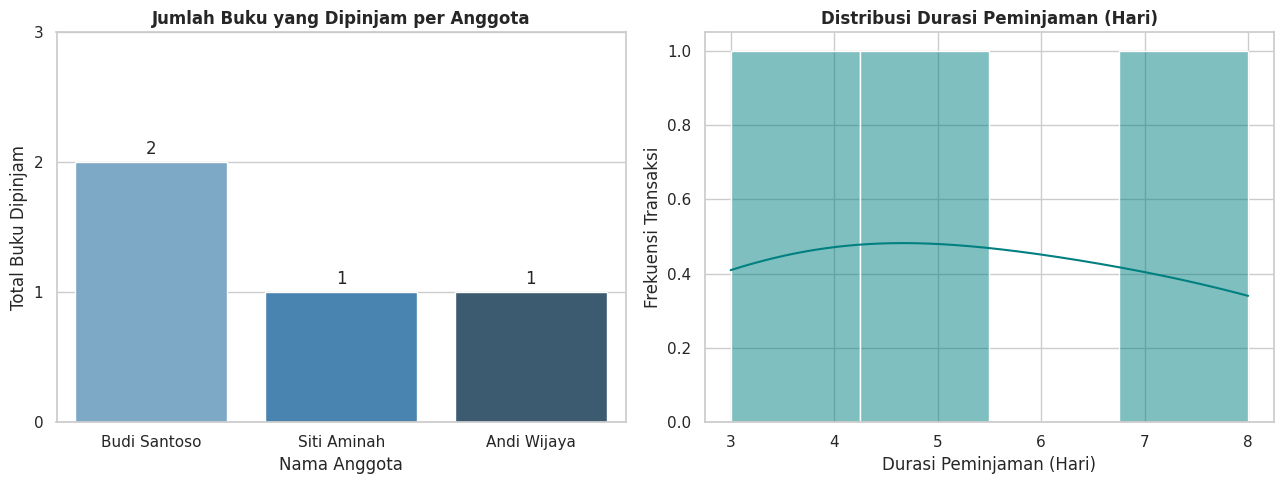

In [5]:
# Mengatur gaya visualisasi
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Diagram Batang Jumlah Buku Dipinjam per Anggota
sns.barplot(
    data=df_agregasi,
    x='nama_anggota',
    y='total_buku_dipinjam',
    palette='Blues_d',
    hue='nama_anggota',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Jumlah Buku yang Dipinjam per Anggota', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Nama Anggota')
axes[0].set_ylabel('Total Buku Dipinjam')
axes[0].set_yticks(range(0, int(df_agregasi['total_buku_dipinjam'].max()) + 2))

# Menambahkan label angka di atas batang
for container in axes[0].containers:
    axes[0].bar_label(container, padding=3)

# Plot 2: Distribusi Durasi Peminjaman (Histogram)
durasi_valid = df_peminjaman['durasi_hari'].dropna()
sns.histplot(
    durasi_valid,
    bins=4,
    kde=True,
    color='teal',
    ax=axes[1]
)
axes[1].set_title('Distribusi Durasi Peminjaman (Hari)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Durasi Peminjaman (Hari)')
axes[1].set_ylabel('Frekuensi Transaksi')

plt.tight_layout()
plt.show()

# Tutup koneksi database setelah seluruh proses selesai
conn.close()